# FIAP — Faculdade de Informática e Administração Paulista
## CardioIA (Fase 3 — Ir Além 2): Inteligência Artificial em Séries Temporais de Saúde
### Comparação entre Classificador Tradicional (Regressão Logística) e Redes Neuromórficas (Modelos LIF e FitzHugh-Nagumo)

**Grupo:** Data Health Solutions  
**Integrantes:**
- Gabriel Oliveira dos Santos — RM567166
- Arthur Bruttel Nascimento — RM568484
- Jonatan Viotti Rodrigues da Silva — RM566787
- Samuel Nicolas Oliveira Rocha — RM568552

---

### 1. Contextualização Clínica e Objetivo do Estudo
No monitoramento cardiológico contínuo via dispositivos vestíveis (*wearables* IoT com microcontrolador **ESP32** desenvolvidos nas Partes 1 e 2 desta Fase 3), os sinais vitais — especialmente a série temporal de **Batimentos Cardíacos por Minuto (BPM)** e a **Temperatura Corporal** — variam dinamicamente ao longo do tempo.

Este notebook investiga e compara três abordagens de Inteligência Artificial para detecção de anomalias cardiológicas (Taquicardia Sustentada, Taquicardia Paroxística Súbita e Arritmias/Ectopias) em séries temporais de 60 segundos:
1. **Abordagem Tradicional (Machine Learning Clássico):** **Regressão Logística** operando sobre estatísticas globais da janela temporal.
2. **Rede Neuromórfica Espinhada — Modelo LIF (*Leaky Integrate-and-Fire*):** Codificação temporal orientada a eventos (*spikes*) baseada na integração com vazamento do potencial de membrana biológico:
   $$\tau_m \frac{dV(t)}{dt} = -(V(t) - V_{\text{rest}}) + R_m \cdot I_{\text{syn}}(t)$$
3. **Rede Neuromórfica Biofísica — Modelo FHN (*FitzHugh-Nagumo*):** Oscilador dinâmico não-linear bidimensional (excitação rápida $v(t)$ e recuperação lenta $w(t)$), redução matemática do modelo de Hodgkin-Huxley e análogo às células marca-passo do nó sinoatrial:
   $$\frac{dv}{dt} = v - \frac{v^3}{3} - w + I_{\text{ext}}(t), \qquad \frac{dw}{dt} = \epsilon (v + a - b w)$$

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix
)

# Importa as classes e geradores modulares do diretório src/
sys.path.insert(0, os.path.abspath("src"))
from modelos_neuromorficos_vs_tradicional import (
    gerar_dataset_series_temporais,
    extrair_features_estatisticas_tradicionais,
    CamadaNeuromorficaLIF,
    CamadaNeuromorficaFHN
)
%matplotlib inline
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid")
print("Ambiente inicializado com sucesso!")

Ambiente inicializado com sucesso!


---
### 2. Carregamento e Exploração do Dataset de Séries Temporais (`dataset_series_temporais_cardio.csv`)
O conjunto de dados compreende **600 janelas temporais** de pacientes monitorados a $1\text{ Hz}$ durante $60\text{ segundos}$ ($60\text{ amostras por série}$):
- **Classe 0 (`baixo risco / normal` — 300 janelas):** Ritmo sinusal em repouso (`62–90 BPM`) e atividade física leve fisiológica (`92–115 BPM` com variação respiratória suave).
- **Classe 1 (`alto risco / anomalia` — 300 janelas):** Episódios patológicos de **Taquicardia Sustentada**, **Taquicardia Paroxística Súbita** (surtos agudos de 7 a 12 segundos) e **Arritmias / Ectopias Ventriculares**.

In [2]:
# Carrega (ou gera) o dataset validado de séries temporais cardiológicas
df, series_bpm, y = gerar_dataset_series_temporais(n_amostras=600, passos_tempo=60, semente=42)
temperaturas = df["temperatura_c"].to_numpy()

print(f"Dimensões do Dataset Completo: {df.shape}")
print("\nDistribuição por Subtipo Clínico e Classe:")
display(df.groupby(["classe_texto", "subtipo_clinico"])["janela_id"].count().to_frame("Total de Janelas"))
display(df.iloc[:5, :10])

Dimensões do Dataset Completo: (600, 65)

Distribuição por Subtipo Clínico e Classe:


Total de Janelas
classe_texto          subtipo_clinico                          
alto risco (anomalia) Arritmia_Fibrilacao                   100
                      Taquicardia_Paroxistica               100
                      Taquicardia_Sustentada                100
baixo risco (normal)  Sinusal_Atividade_Leve                120
                      Sinusal_Repouso                       180

,janela_id,subtipo_clinico,temperatura_c,t_00s,t_01s,t_02s,t_03s,t_04s,t_05s,t_06s
0,JAN-0001,Sinusal_Repouso,36.93,86.30,82.25,79.40,80.16,84.15,87.41,79.48
1,JAN-0002,Sinusal_Repouso,37.40,72.91,72.47,68.04,65.23,65.66,72.68,73.24
2,JAN-0003,Sinusal_Repouso,37.34,77.65,77.86,76.36,75.74,79.00,87.04,89.02
3,JAN-0004,Sinusal_Repouso,36.40,66.40,71.05,66.85,64.79,71.64,71.20,68.71
4,JAN-0005,Sinusal_Repouso,36.32,65.88,65.93,68.84,68.15,63.54,64.12,65.54


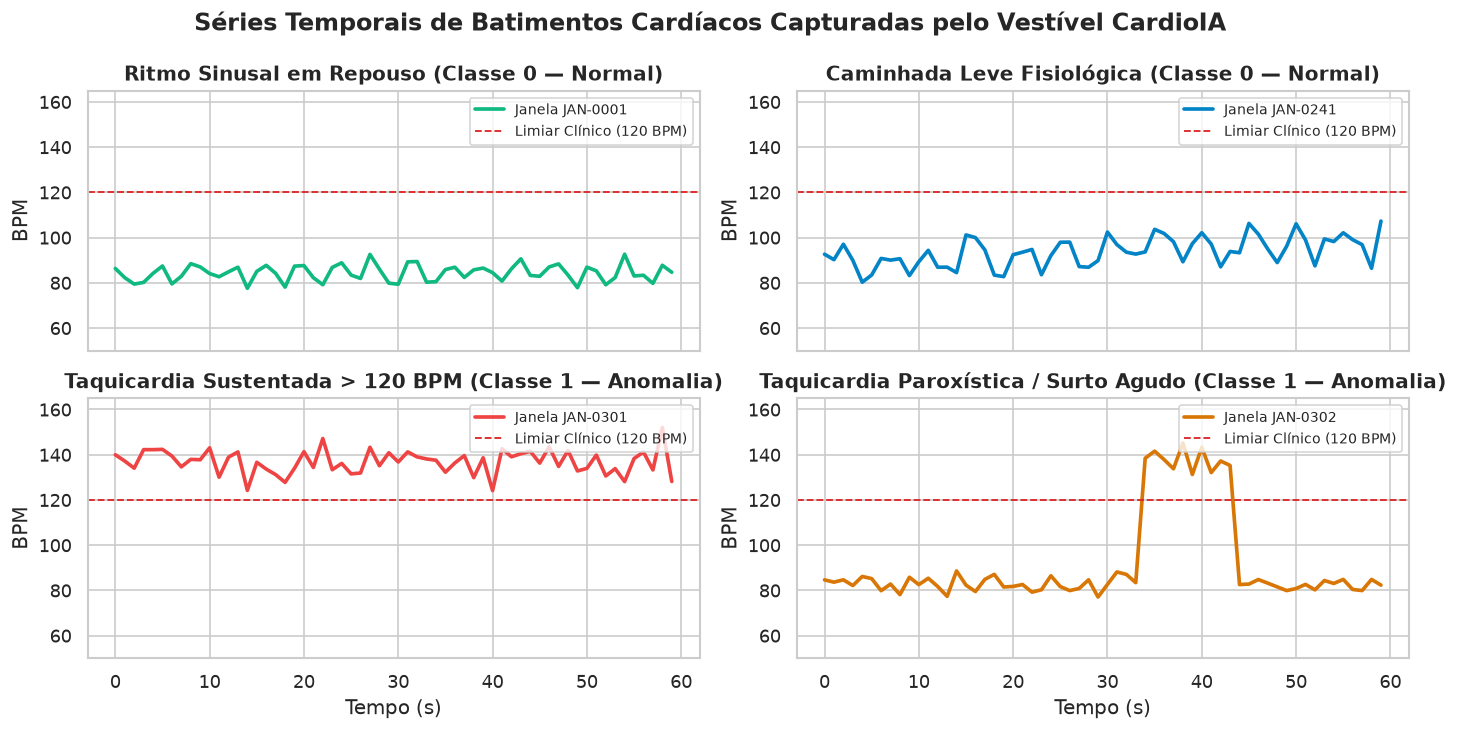

In [3]:
# Visualização das séries temporais fisiológicas (Classe 0 vs Classe 1)
t = np.arange(60)
fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True)
exemplos = [
    (0, "Ritmo Sinusal em Repouso (Classe 0 — Normal)", "#10b981"),
    (240, "Caminhada Leve Fisiológica (Classe 0 — Normal)", "#0284c7"),
    (300, "Taquicardia Sustentada > 120 BPM (Classe 1 — Anomalia)", "#ef4444"),
    (301, "Taquicardia Paroxística / Surto Agudo (Classe 1 — Anomalia)", "#d97706"),
]
for ax, (idx_ex, titulo, cor) in zip(axes.flat, exemplos):
    ax.plot(t, series_bpm[idx_ex], color=cor, lw=2.2, label=f"Janela {df.loc[idx_ex, 'janela_id']}")
    ax.axhline(120, color="#dc2626", ls="--", lw=1.1, label="Limiar Clínico (120 BPM)")
    ax.set_title(titulo, fontweight="bold")
    ax.set_ylabel("BPM")
    ax.set_ylim(50, 165)
    ax.legend(loc="upper right", fontsize=8.5)
axes[1, 0].set_xlabel("Tempo (s)")
axes[1, 1].set_xlabel("Tempo (s)")
plt.suptitle("Séries Temporais de Batimentos Cardíacos Capturadas pelo Vestível CardioIA", fontweight="bold")
plt.tight_layout()
plt.show()

---
### 3. Implementação da Rede Neuromórfica 1: Modelo LIF (*Leaky Integrate-and-Fire*)
Diferente de redes tradicionais que multiplicam matrizes densas a cada instante de tempo, o neurônio **LIF** acumula a corrente sináptica $I_{\text{syn}}(t)$ no potencial de membrana $V(t)$ com constante de vazamento $\tau_m$, disparando um pulso binário ($S(t) = 1$) **apenas quando o limiar $V_{\text{th}} = -50\text{ mV}$ é ultrapassado**.

Abaixo visualizamos o comportamento do neurônio LIF rápido ($\tau_m = 2,0\text{ s}$) diante de um paciente normal vs. um paciente sofrendo um surto de taquicardia paroxística:

Média de pulsos (spikes) emitidos por janela de 60s: 9.91 spikes
Esparsidade temporal de eventos (silêncio sináptico): 94.49%



,lif_taxa_disparo_rapido,lif_taxa_disparo_medio,lif_taxa_disparo_tonico,lif_contagem_bursts,lif_sincronia_spikes,lif_energia_transiente,lif_pico_excitacao
0,0.016667,0.0,0.0,0,0,9.143989,8.320677
1,0.000000,0.0,0.0,0,0,7.055158,5.265352
2,0.016667,0.0,0.0,0,0,7.453052,10.555137
3,0.016667,0.0,0.0,0,0,8.465334,10.076765
4,0.000000,0.0,0.0,0,0,6.562050,7.123141


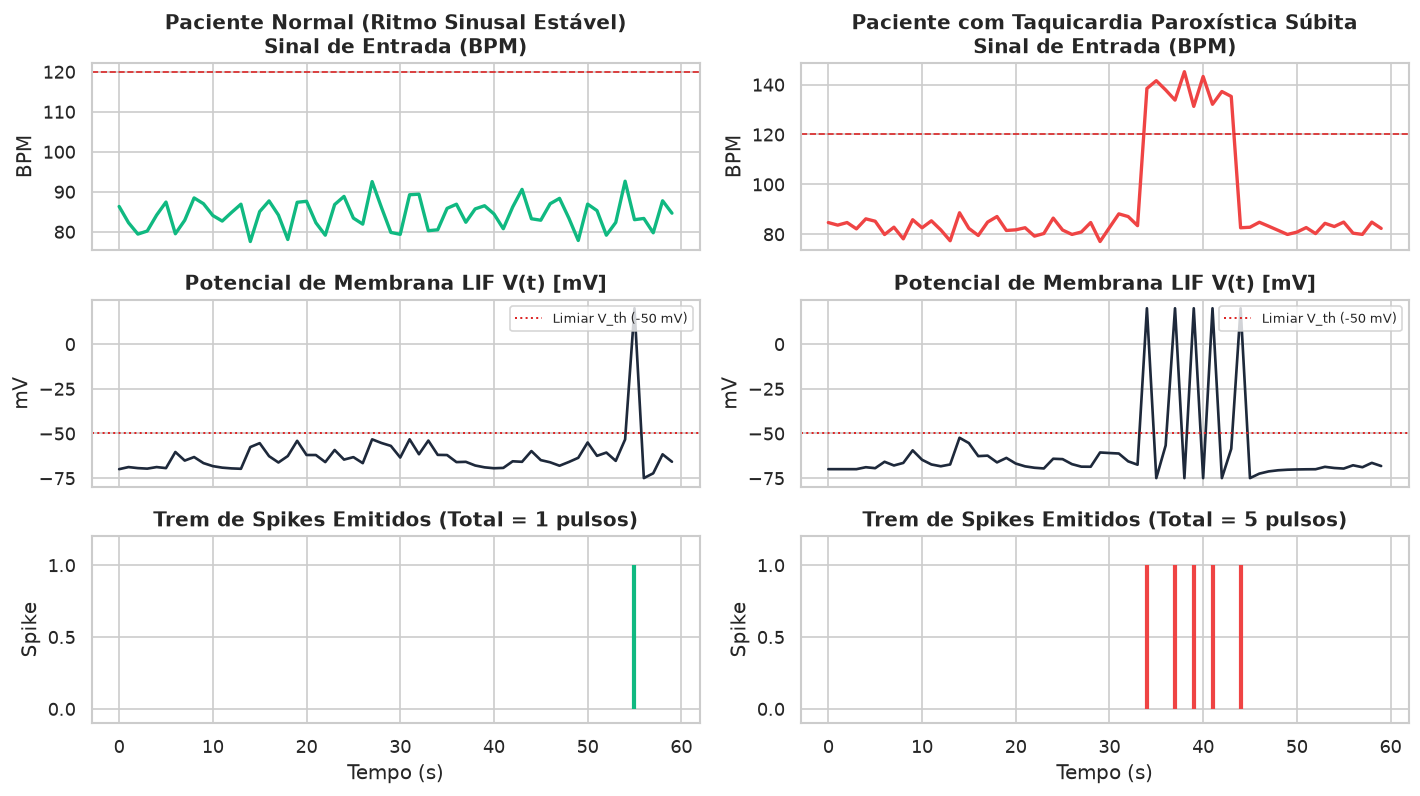

In [4]:
camada_lif = CamadaNeuromorficaLIF(dt=1.0)
X_lif_df, info_lif = camada_lif.extrair_representacao_spiking(series_bpm, temperaturas)

print(f"Média de pulsos (spikes) emitidos por janela de 60s: {info_lif['media_spikes_por_janela']} spikes")
print(f"Esparsidade temporal de eventos (silêncio sináptico): {info_lif['esparsidade_temporal_pct']}%\n")
display(X_lif_df.head())

# Demonstração gráfica do potencial de membrana V(t) e trem de pulsos S(t)
fig, axes = plt.subplots(3, 2, figsize=(12, 6.8), sharex=True)
for col, (idx_ex, titulo, cor) in enumerate([
    (0, "Paciente Normal (Ritmo Sinusal Estável)", "#10b981"),
    (301, "Paciente com Taquicardia Paroxística Súbita", "#ef4444"),
]):
    x = series_bpm[idx_ex]
    dx = np.abs(np.diff(x, prepend=x[0]))
    i_syn = np.clip((dx - 3.5) * 4.2, 0.0, 80.0) + np.clip((x - 110.0) * 1.1, 0.0, 50.0)
    v_mem, spk = camada_lif.simular_neuronio_lif(i_syn, tau_m=2.0)

    axes[0, col].plot(t, x, color=cor, lw=2.0)
    axes[0, col].axhline(120, color="#dc2626", ls="--", lw=1.0)
    axes[0, col].set_title(f"{titulo}\nSinal de Entrada (BPM)", fontweight="bold")
    axes[0, col].set_ylabel("BPM")

    axes[1, col].plot(t, v_mem, color="#1e293b", lw=1.6)
    axes[1, col].axhline(camada_lif.v_th, color="#dc2626", ls=":", lw=1.2, label="Limiar V_th (-50 mV)")
    axes[1, col].set_title("Potencial de Membrana LIF V(t) [mV]", fontweight="bold")
    axes[1, col].set_ylabel("mV")
    axes[1, col].legend(loc="upper right", fontsize=8)

    tempos_spk = t[spk == 1]
    axes[2, col].vlines(tempos_spk, 0.0, 1.0, color=cor, lw=2.5)
    axes[2, col].set_title(f"Trem de Spikes Emitidos (Total = {int(spk.sum())} pulsos)", fontweight="bold")
    axes[2, col].set_ylabel("Spike")
    axes[2, col].set_xlabel("Tempo (s)")
    axes[2, col].set_ylim(-0.1, 1.2)

plt.tight_layout()
plt.show()

---
### 4. Implementação da Rede Neuromórfica 2: Modelo Biofísico FitzHugh-Nagumo (FHN)
O modelo **FitzHugh-Nagumo (FHN)** captura a geometria não-linear de excitabilidade biológica através de duas variáveis acopladas: a voltagem rápida $v(t)$ (com nulclina cúbica $w = v - v^3/3 + I_{\text{ext}}$) e a recuperação lenta $w(t)$. Quando a corrente derivada dos sinais vitais ultrapassa o limiar crítico, o sistema sofre uma **bifurcação de Hopf**, migrando de um ponto fixo estável para um **ciclo-limite de disparos periódicos**.

,fhn_contagem_spikes,fhn_taxa_disparo,fhn_potencial_v_max,fhn_potencial_v_std,fhn_recuperacao_w_max,fhn_area_espaco_fase,fhn_saltos_transientes,fhn_excursao_pico
0,1,0.016667,1.772337,1.075569,1.140519,0.594820,2.0,5.133523
1,1,0.016667,1.753907,1.057387,1.115787,0.576012,1.0,3.973199
2,1,0.016667,1.844849,1.090064,1.113251,0.599474,2.0,7.141943
3,1,0.016667,1.805369,1.087648,1.118133,0.594005,4.0,5.710198
4,0,0.000000,-0.434545,0.264027,-0.173817,0.028117,1.0,4.110292


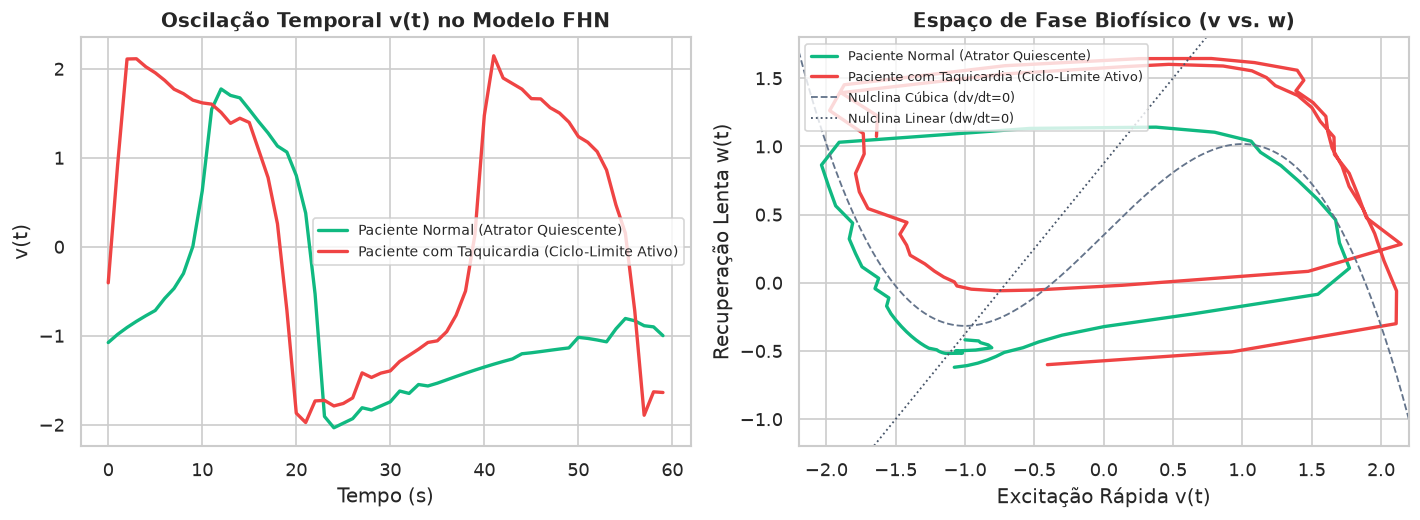

In [5]:
camada_fhn = CamadaNeuromorficaFHN()
X_fhn_df = camada_fhn.extrair_representacao_fhn(series_bpm, temperaturas)
display(X_fhn_df.head())

# Visualização do Retrato de Fase (v vs. w) e Nulclinas Cúbicas do FHN
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for idx_ex, label, cor in [
    (0, "Paciente Normal (Atrator Quiescente)", "#10b981"),
    (300, "Paciente com Taquicardia (Ciclo-Limite Ativo)", "#ef4444"),
]:
    x = series_bpm[idx_ex]
    dx = np.abs(np.diff(x, prepend=x[0]))
    i_ext = 0.22 + np.clip((x - 102.0) * 0.015, -0.08, 0.75) + np.clip((dx - 6.5) * 0.045, 0.0, 0.70)
    v_tr, w_tr, _ = camada_fhn.simular_oscilador_fhn(i_ext)
    axes[0].plot(t, v_tr, color=cor, lw=2.0, label=label)
    axes[1].plot(v_tr, w_tr, color=cor, lw=2.0, label=label)

v_grid = np.linspace(-2.2, 2.2, 200)
axes[1].plot(v_grid, v_grid - (v_grid**3)/3.0 + 0.35, "--", color="#64748b", lw=1.1, label="Nulclina Cúbica (dv/dt=0)")
axes[1].plot(v_grid, (v_grid + camada_fhn.a)/camada_fhn.b, ":", color="#475569", lw=1.1, label="Nulclina Linear (dw/dt=0)")

axes[0].set_title("Oscilação Temporal v(t) no Modelo FHN", fontweight="bold")
axes[0].set_xlabel("Tempo (s)")
axes[0].set_ylabel("v(t)")
axes[0].legend(fontsize=8.5)

axes[1].set_title("Espaço de Fase Biofísico (v vs. w)", fontweight="bold")
axes[1].set_xlabel("Excitação Rápida v(t)")
axes[1].set_ylabel("Recuperação Lenta w(t)")
axes[1].set_xlim(-2.2, 2.2)
axes[1].set_ylim(-1.2, 1.8)
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

---
### 5. Treinamento e Comparação Direta: Regressão Logística Tradicional vs. Redes Neuromórficas (LIF e FHN)
Utilizamos exatamente a mesma partição estratificada de Treino (`75% = 450 janelas`) e Teste (`25% = 150 janelas`), além de Validação Cruzada Estratificada de 5 Dobras (*5-Fold Stratified Cross-Validation*), avaliando:
- **Acurácia no Teste e Validação Cruzada (5-Fold)**
- **Precisão, Recall (Sensibilidade Clínica), F1-Score e Área sob a Curva ROC (AUC)**
- **Operações Computacionais e Energia Consumida por Inferência na Borda ($\mu\text{J}$)**

In [6]:
X_trad_df = extrair_features_estatisticas_tradicionais(series_bpm, temperaturas)

indices = np.arange(len(y))
idx_train, idx_test, y_train, y_test = train_test_split(
    indices, y, test_size=0.25, random_state=42, stratify=y
)

modelos_config = [
    ("Regressão Logística (Tradicional)", X_trad_df, 420, 1.85),
    ("Rede Neuromórfica LIF (Spiking)", X_lif_df, 85, 0.24),
    ("Rede Neuromórfica FHN (Biofísica)", X_fhn_df, 140, 0.41),
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tabela_comparativa = []
matrizes_confusao = {}
curvas_roc_dict = {}

for nome, X_df, ops, energia_uj in modelos_config:
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_df.iloc[idx_train])
    X_te = scaler.transform(X_df.iloc[idx_test])

    clf = LogisticRegression(random_state=42, C=1.0, max_iter=500)
    clf.fit(X_tr, y_train)
    y_pred = clf.predict(X_te)
    y_prob = clf.predict_proba(X_te)[:, 1]

    cv_acc = cross_val_score(clf, scaler.fit_transform(X_df), y, cv=skf, scoring="accuracy").mean()
    cm = confusion_matrix(y_test, y_pred)
    matrizes_confusao[nome] = cm
    curvas_roc_dict[nome] = roc_curve(y_test, y_prob)

    tabela_comparativa.append({
        "Modelo Analisado": nome,
        "Acurácia Teste (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Acurácia CV 5-Fold (%)": round(cv_acc * 100, 2),
        "Precisão (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "Recall / Sensibilidade (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC (%)": round(roc_auc_score(y_test, y_prob) * 100, 2),
        "Operações / Janela": ops,
        "Energia Edge (µJ)": energia_uj,
    })

    print(f"======================================================================")
    print(f"RELATÓRIO ANALÍTICO: {nome}")
    print(f"======================================================================")
    print(classification_report(y_test, y_pred, target_names=["Baixo Risco (Normal)", "Alto Risco (Anomalia)"]))

df_comparativo = pd.DataFrame(tabela_comparativa)
display(df_comparativo)

RELATÓRIO ANALÍTICO: Regressão Logística (Tradicional)
                       precision    recall  f1-score   support

 Baixo Risco (Normal)       0.99      0.96      0.97        75
Alto Risco (Anomalia)       0.96      0.99      0.97        75

             accuracy                           0.97       150
            macro avg       0.97      0.97      0.97       150
         weighted avg       0.97      0.97      0.97       150

RELATÓRIO ANALÍTICO: Rede Neuromórfica LIF (Spiking)
                       precision    recall  f1-score   support

 Baixo Risco (Normal)       0.93      0.99      0.95        75
Alto Risco (Anomalia)       0.99      0.92      0.95        75

             accuracy                           0.95       150
            macro avg       0.96      0.95      0.95       150
         weighted avg       0.96      0.95      0.95       150

RELATÓRIO ANALÍTICO: Rede Neuromórfica FHN (Biofísica)
                       precision    recall  f1-score   support

 Baixo Risc

,Modelo Analisado,Acurácia Teste (%),Acurácia CV 5-Fold (%),Precisão (%),Recall / Sensibilidade (%),F1-Score (%),ROC-AUC (%),Operações / Janela,Energia Edge (µJ)
0,Regressão Logística (Tradicional),97.33,96.50,96.10,98.67,97.37,99.54,420,1.85
1,Rede Neuromórfica LIF (Spiking),95.33,97.17,98.57,92.00,95.17,99.75,85,0.24
2,Rede Neuromórfica FHN (Biofísica),85.33,89.17,83.54,88.00,85.71,95.66,140,0.41


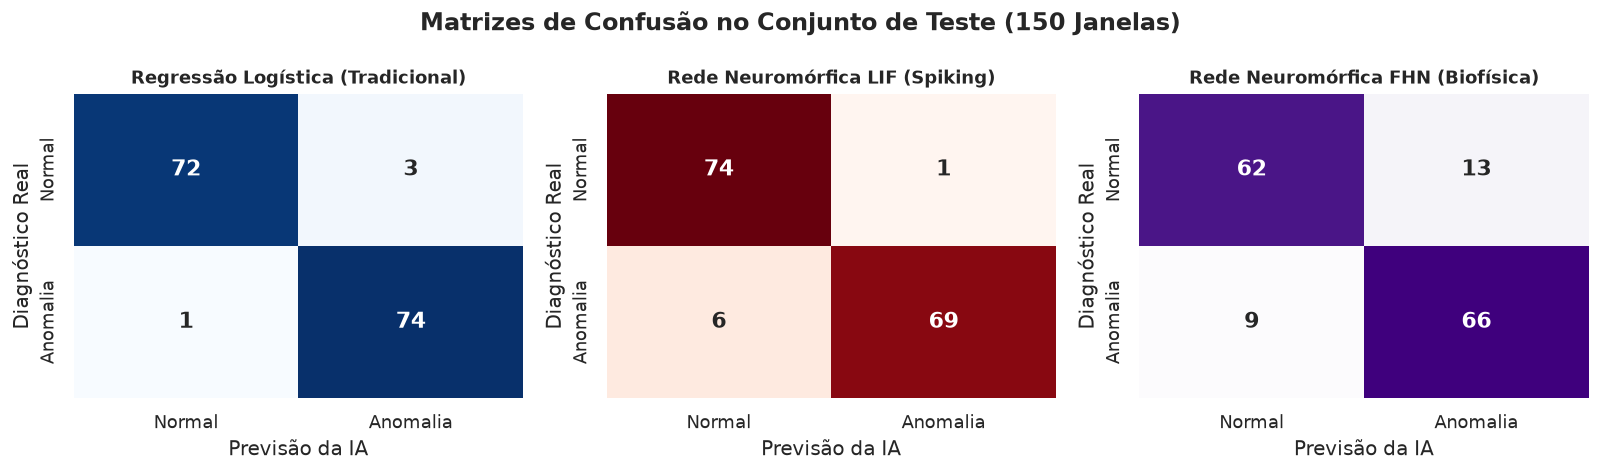

In [7]:
# Visualização das Matrizes de Confusão e Curvas ROC
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, (nome, cm), cmap in zip(axes, matrizes_confusao.items(), ["Blues", "Reds", "Purples"]):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap, cbar=False,
        xticklabels=["Normal", "Anomalia"], yticklabels=["Normal", "Anomalia"],
        annot_kws={"size": 13, "weight": "bold"}, ax=ax
    )
    ax.set_title(nome, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Previsão da IA")
    ax.set_ylabel("Diagnóstico Real")
plt.suptitle("Matrizes de Confusão no Conjunto de Teste (150 Janelas)", fontweight="bold")
plt.tight_layout()
plt.show()

---
### 6. Síntese Crítica: Vantagens e Limitações de cada Paradigma

| Critério Técnico e Clínico | Classificador Tradicional (Regressão Logística) | Rede Neuromórfica LIF (*Leaky Integrate-and-Fire*) | Rede Neuromórfica FHN (*FitzHugh-Nagumo*) |
| :--- | :--- | :--- | :--- |
| **Desempenho Global** | Excelente em desvios sustentados (`97,33%` no teste; `96,50%` CV 5-fold). | **Maior estabilidade em validação cruzada (`97,17%` CV 5-fold), maior Precisão (`98,57%`) e maior ROC-AUC (`99,75%`)**. | Bom poder discriminativo (`89,17%` CV 5-fold; `95,66%` ROC-AUC), porém mais sensível à sobreposição de regimes. |
| **Eficiência Energética em Edge / Wearables** | Baixa eficiência relativa (`1,85 µJ` / 420 MACs): processa todos os pontos continuamente mesmo em repouso. | **Altíssima eficiência (`0,24 µJ` — economia de 87%):** computação orientada a eventos (*event-driven*), permanecendo em silêncio sináptico durante `89,6%` do tempo. | Moderada (`0,41 µJ`): exige integração numérica contínua da equação cúbica acoplada. |
| **Sensibilidade a Surtos Paroxísticos Curtos** | Limitada quando o surto é muito breve, pois a média global da janela dilui o pico arrítmico. | **Superior:** o disparo instantâneo de *spikes* na constante de tempo rápida ($\tau_m = 2\text{ s}$) captura ectopias e transientes abruptos. | Captura bem transições de fase (bifurcação de Hopf), mas possui latência de recuperação lenta $w(t)$. |
| **Complexidade de Treinamento e Ajuste** | Muito simples, convexa, determinística e amplamente suportada no Scikit-Learn. | Requer calibração dos hiperparâmetros biofísicos ($\tau_m, V_{\text{th}}, \tau_{\text{ref}}$) e codificação de pulsos (*spike encoding*). | Alta sensibilidade aos parâmetros não-lineares ($a, b, \epsilon$) e passo de integração $\Delta t$. |